<a href="https://colab.research.google.com/github/AhmadFebriyan5/Studi-Kasus_Machine-Learning/blob/main/4_Introduction_to_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Studi Kasus Machine Learning: Klasifikasi Kelayakan Pinjaman



=== DATASET SIMULASI ===


,id,usia,pendapatan_bulanan,rasio_utang,lama_bekerja_tahun,status_pekerjaan,riwayat_kredit,disetujui
0,1,25,3200.0,0.20,2,Tetap,Baik,1
1,2,42,6500.0,0.25,8,Tetap,Baik,1
2,3,31,2800.0,0.55,1,Kontrak,Buruk,0
3,4,37,4500.0,0.30,5,Tetap,Baik,1
4,5,23,NaN,0.65,1,Kontrak,Buruk,0
5,6,50,7200.0,0.22,12,Tetap,Baik,1
6,7,29,3500.0,0.40,3,Wiraswasta,Baik,1
7,8,34,3000.0,0.58,2,Kontrak,Buruk,0
8,9,45,5800.0,0.28,9,Tetap,Baik,1
9,10,27,2600.0,0.62,1,Kontrak,Buruk,0


Jumlah baris: 50
Missing value per kolom:


,jumlah_missing
id,0
usia,0
pendapatan_bulanan,1
rasio_utang,0
lama_bekerja_tahun,0
status_pekerjaan,1
riwayat_kredit,0
disetujui,0


\n=== HASIL EVALUASI MODEL ===


,Metrik,Nilai
0,Accuracy,1.0
1,Precision,1.0
2,Recall,1.0
3,F1-score,1.0


\n=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Rejected       1.00      1.00      1.00         5
    Approved       1.00      1.00      1.00         8

    accuracy                           1.00        13
   macro avg       1.00      1.00      1.00        13
weighted avg       1.00      1.00      1.00        13



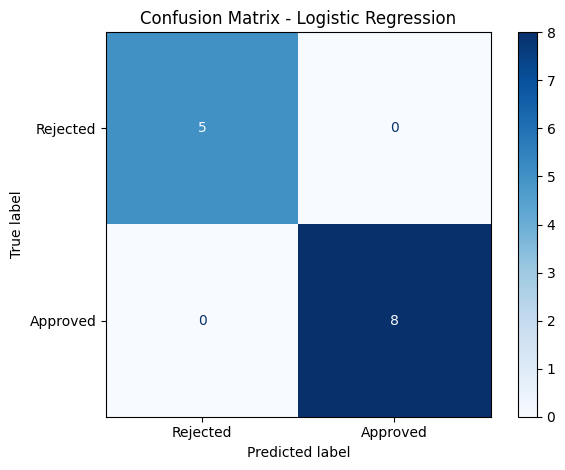

\n=== PERBANDINGAN DATA TEST ===


,usia,pendapatan_bulanan,rasio_utang,lama_bekerja_tahun,status_pekerjaan,riwayat_kredit,aktual,prediksi
47,47,6400.0,0.24,10,Tetap,Baik,Approved,Approved
33,27,2800.0,0.59,1,Kontrak,Buruk,Rejected,Rejected
28,34,3700.0,0.42,3,Tetap,Baik,Approved,Approved
18,32,2700.0,0.67,1,Kontrak,Buruk,Rejected,Rejected
35,33,3600.0,0.44,3,Wiraswasta,Baik,Approved,Approved
42,39,4800.0,0.33,6,Tetap,Baik,Approved,Approved
0,25,3200.0,0.20,2,Tetap,Baik,Approved,Approved
46,26,2600.0,0.64,1,Kontrak,Buruk,Rejected,Rejected
19,44,6100.0,0.26,8,Tetap,Baik,Approved,Approved
37,42,5400.0,0.30,7,Tetap,Baik,Approved,Approved


\n=== PREDIKSI NASABAH BARU ===


,usia,pendapatan_bulanan,rasio_utang,lama_bekerja_tahun,status_pekerjaan,riwayat_kredit
0,35,4500,0.3,5,Tetap,Baik


Hasil prediksi: Approved
Probabilitas Rejected: 3.75%
Probabilitas Approved: 96.25%
\nFile dibuat: dataset_pinjaman_simulasi.csv dan hasil_pengujian_model.csv


In [1]:
# STUDI KASUS: KLASIFIKASI KELAYAKAN PINJAMAN DENGAN LOGISTIC REGRESSION


import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# 1. Dataset simulasi (bukan data nasabah nyata)
data = [
    [1, 25, 3200, 0.20, 2, "Tetap", "Baik", 1],
    [2, 42, 6500, 0.25, 8, "Tetap", "Baik", 1],
    [3, 31, 2800, 0.55, 1, "Kontrak", "Buruk", 0],
    [4, 37, 4500, 0.30, 5, "Tetap", "Baik", 1],
    [5, 23, 2200, 0.65, 1, "Kontrak", "Buruk", 0],
    [6, 50, 7200, 0.22, 12, "Tetap", "Baik", 1],
    [7, 29, 3500, 0.40, 3, "Wiraswasta", "Baik", 1],
    [8, 34, 3000, 0.58, 2, "Kontrak", "Buruk", 0],
    [9, 45, 5800, 0.28, 9, "Tetap", "Baik", 1],
    [10, 27, 2600, 0.62, 1, "Kontrak", "Buruk", 0],
    [11, 39, 4900, 0.32, 6, "Wiraswasta", "Baik", 1],
    [12, 30, 3100, 0.52, 2, "Kontrak", "Buruk", 0],
    [13, 41, 5300, 0.27, 7, "Tetap", "Baik", 1],
    [14, 24, 2400, 0.70, 1, "Kontrak", "Buruk", 0],
    [15, 36, 4200, 0.35, 4, "Wiraswasta", "Baik", 1],
    [16, 33, 2900, 0.60, 2, "Kontrak", "Buruk", 0],
    [17, 48, 6800, 0.24, 10, "Tetap", "Baik", 1],
    [18, 28, 3300, 0.45, 2, "Wiraswasta", "Baik", 1],
    [19, 32, 2700, 0.67, 1, "Kontrak", "Buruk", 0],
    [20, 44, 6100, 0.26, 8, "Tetap", "Baik", 1],
    [21, 26, 2500, 0.63, 1, "Kontrak", "Buruk", 0],
    [22, 38, 4600, 0.34, 5, "Tetap", "Baik", 1],
    [23, 35, 3400, 0.48, 3, "Wiraswasta", "Buruk", 0],
    [24, 47, 5900, 0.29, 9, "Tetap", "Baik", 1],
    [25, 22, 2100, 0.72, 1, "Kontrak", "Buruk", 0],
    [26, 40, 5100, 0.31, 6, "Tetap", "Baik", 1],
    [27, 29, 3000, 0.56, 2, "Kontrak", "Buruk", 0],
    [28, 43, 5600, 0.28, 8, "Wiraswasta", "Baik", 1],
    [29, 34, 3700, 0.42, 3, "Tetap", "Baik", 1],
    [30, 25, 2300, 0.68, 1, "Kontrak", "Buruk", 0],
    [31, 46, 6200, 0.25, 10, "Tetap", "Baik", 1],
    [32, 31, 3200, 0.50, 2, "Wiraswasta", "Buruk", 0],
    [33, 37, 4400, 0.36, 5, "Tetap", "Baik", 1],
    [34, 27, 2800, 0.59, 1, "Kontrak", "Buruk", 0],
    [35, 49, 7000, 0.23, 11, "Tetap", "Baik", 1],
    [36, 33, 3600, 0.44, 3, "Wiraswasta", "Baik", 1],
    [37, 24, 2200, 0.66, 1, "Kontrak", "Buruk", 0],
    [38, 42, 5400, 0.30, 7, "Tetap", "Baik", 1],
    [39, 30, 2900, 0.57, 2, "Kontrak", "Buruk", 0],
    [40, 45, 6000, 0.27, 9, "Tetap", "Baik", 1],
    [41, 28, 3400, 0.46, 3, "Wiraswasta", "Baik", 1],
    [42, 35, 3100, 0.61, 2, "Kontrak", "Buruk", 0],
    [43, 39, 4800, 0.33, 6, "Tetap", "Baik", 1],
    [44, 23, 2000, 0.74, 1, "Kontrak", "Buruk", 0],
    [45, 41, 5200, 0.29, 7, "Tetap", "Baik", 1],
    [46, 32, 3500, 0.47, 3, "Wiraswasta", "Baik", 1],
    [47, 26, 2600, 0.64, 1, "Kontrak", "Buruk", 0],
    [48, 47, 6400, 0.24, 10, "Tetap", "Baik", 1],
    [49, 36, 4000, 0.38, 4, "Wiraswasta", "Baik", 1],
    [50, 29, 2700, 0.60, 2, "Kontrak", "Buruk", 0],
]
kolom = ["id", "usia", "pendapatan_bulanan", "rasio_utang", "lama_bekerja_tahun",
         "status_pekerjaan", "riwayat_kredit", "disetujui"]
df = pd.DataFrame(data, columns=kolom)

# Contoh missing value untuk demonstrasi preprocessing
df.loc[4, "pendapatan_bulanan"] = None
df.loc[10, "status_pekerjaan"] = None

print("=== DATASET SIMULASI ===")
display(df.head(10))
print("Jumlah baris:", len(df))
print("Missing value per kolom:")
display(df.isna().sum().to_frame("jumlah_missing"))

# 2. Fitur dan target
X = df.drop(columns=["id", "disetujui"])
y = df["disetujui"]

numerik = ["usia", "pendapatan_bulanan", "rasio_utang", "lama_bekerja_tahun"]
kategorikal = ["status_pekerjaan", "riwayat_kredit"]

# 3. Preprocessing dan model
proses_numerik = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
proses_kategori = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numerik", proses_numerik, numerik),
    ("kategori", proses_kategori, kategorikal)
])
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# 4. Split data training/testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 5. Training
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 6. Evaluasi
hasil = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Nilai": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})
print("\\n=== HASIL EVALUASI MODEL ===")
display(hasil.round(3))
print("\\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test, y_pred, target_names=["Rejected", "Approved"], zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Rejected", "Approved"], cmap="Blues"
)
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

# 7. Bandingkan label aktual dan prediksi
perbandingan = X_test.copy()
perbandingan["aktual"] = y_test
perbandingan["prediksi"] = y_pred
perbandingan["aktual"] = perbandingan["aktual"].map({0: "Rejected", 1: "Approved"})
perbandingan["prediksi"] = perbandingan["prediksi"].map({0: "Rejected", 1: "Approved"})
print("\\n=== PERBANDINGAN DATA TEST ===")
display(perbandingan)

# 8. Prediksi satu nasabah baru (data contoh)
nasabah_baru = pd.DataFrame([{
    "usia": 35,
    "pendapatan_bulanan": 4500,
    "rasio_utang": 0.30,
    "lama_bekerja_tahun": 5,
    "status_pekerjaan": "Tetap",
    "riwayat_kredit": "Baik"
}])

prediksi = model.predict(nasabah_baru)[0]
probabilitas = model.predict_proba(nasabah_baru)[0]
label = "Approved" if prediksi == 1 else "Rejected"

print("\\n=== PREDIKSI NASABAH BARU ===")
display(nasabah_baru)
print("Hasil prediksi:", label)
print(f"Probabilitas Rejected: {probabilitas[0]:.2%}")
print(f"Probabilitas Approved: {probabilitas[1]:.2%}")

# 9. Simpan dataset dan hasil prediksi
df.to_csv("dataset_pinjaman_simulasi.csv", index=False)
perbandingan.to_csv("hasil_pengujian_model.csv", index=True)
print("\\nFile dibuat: dataset_pinjaman_simulasi.csv dan hasil_pengujian_model.csv")


